# COMP3032 Part A: greenhouse crop health prediction
**Mohammad Adib (Eddie) Amiri**

**Aim:** predict `next_health_score` from information available at the current simulation step, for an unseen greenhouse episode. This is regression because health is a continuous score between 0 and 1. One step is not necessarily one physical day.

The investigation compares a mean baseline, Ridge regression, a decision tree and support vector regression (SVR). Model and feature choices use only the training episodes. The supplied validation file is the final holdout. Images are reserved for Part B.


## How to run
Place this notebook beside `COMP3032_greenhouse_dataset.zip` or the extracted `COMP3032_greenhouse_dataset` folder. Alternatively set `DATA_LOCATION` below. Restart the kernel and run all cells in order.

Tested with Python 3.12, NumPy 2.3.5, pandas 2.2.3, scikit-learn 1.8.0 and Matplotlib 3.10.8. The shuffled `GroupKFold` needs scikit-learn 1.6 or later. To reproduce the tested environment: `pip install numpy==2.3.5 pandas==2.2.3 scikit-learn==1.8.0 matplotlib==3.10.8 jupyter`.

All report results are saved in this notebook. Running it also recreates tables and figures in `student_part_a_results`; those exports are optional and are not separate submission files. No GPU, images or external Python scripts are needed.


In [1]:
from pathlib import Path
import io
import zipfile
import numpy as np
import pandas as pd
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.model_selection import GroupKFold, GridSearchCV, cross_validate
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

SEED = 42
DATA_LOCATION = None  # Optional: Path('path/to/the/zip_or_extracted_folder')
RESULTS = Path('student_part_a_results')
RESULTS.mkdir(exist_ok=True)
print('Package versions:', np.__version__, pd.__version__, sklearn.__version__, matplotlib.__version__)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

def save_plot(name):
    plt.tight_layout()
    plt.savefig(RESULTS / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()


Package versions: 2.3.5 2.2.3 1.8.0 3.10.8


## 1. Understand and check the data


In [2]:
if DATA_LOCATION is None:
    candidates = []
    for base in [Path.cwd(), Path.cwd().parent]:
        candidates += [base / 'COMP3032_greenhouse_dataset.zip',
                       base / 'upload/COMP3032_greenhouse_dataset.zip',
                       base / 'COMP3032_greenhouse_dataset',
                       base / 'data/COMP3032_greenhouse_dataset']
    DATA_LOCATION = next((p for p in candidates if p.exists()), None)
if DATA_LOCATION is None:
    raise FileNotFoundError('Set DATA_LOCATION to the supplied zip or extracted folder.')
DATA_LOCATION = Path(DATA_LOCATION)

def read_csv(name):
    if DATA_LOCATION.is_dir():
        return pd.read_csv(DATA_LOCATION / name)
    with zipfile.ZipFile(DATA_LOCATION) as archive:
        member = next(p for p in archive.namelist() if Path(p).name == name)
        return pd.read_csv(io.BytesIO(archive.read(member)))

train_raw = read_csv('train.csv')
dictionary = read_csv('data_dictionary.csv')
print('Training shape:', train_raw.shape)
display(dictionary)
display(train_raw.head(3))


Training shape: (10800, 31)


,variable,description
0,episode_id,Trajectory identifier; split only by episode
1,day,Simulation step
2,cultivar,Synthetic cultivar A/B/C
3,season,cool/mild/warm regime
4,action,"0 hold, 1 irrigate, 2 ventilate, 3 heat, 4 sha..."
5,outside_temp_c,Outdoor temperature
6,outside_humidity_pct,Outdoor relative humidity
7,solar_w_m2,Solar radiation
8,inside_temp_c,Greenhouse air temperature
9,inside_humidity_pct,Greenhouse relative humidity


,episode_id,day,cultivar,season,action,action_name,outside_temp_c,outside_humidity_pct,solar_w_m2,inside_temp_c,inside_humidity_pct,co2_ppm,soil_moisture,vpd_kpa,biomass_index,fruit_index,health_score,disease_severity,energy_kwh,water_l,reward,next_inside_temp_c,next_inside_humidity_pct,next_co2_ppm,next_soil_moisture,next_biomass_index,next_health_score,next_disease_severity,next_reward,terminal,image_index
0,0,0,A,cool,5,co2_enrich,17.924048,72.913935,352.372686,22.354688,70.118915,908.497250,0.590503,0.807277,0.092649,0.0,0.951978,0.015243,0.9,0.0,0.077432,21.520641,69.001807,823.726501,0.553137,0.113333,0.901321,0.010821,0.091028,0,0
1,0,1,A,cool,0,hold,19.001957,83.424202,384.569456,21.520641,69.001807,823.726501,0.553137,0.795928,0.113333,0.0,0.901321,0.010821,0.1,0.0,0.091028,21.335199,67.119159,790.990382,0.520063,0.130141,0.888971,0.015960,0.078256,0,1
2,0,2,A,cool,0,hold,20.948762,64.797465,428.958094,21.335199,67.119159,790.990382,0.520063,0.834737,0.130141,0.0,0.888971,0.015960,0.1,0.0,0.078256,21.449921,68.972397,699.116342,0.478745,0.147139,0.852164,0.013878,0.077758,0,2


The dictionary describes `health_score` and `disease_severity` as **latent** variables. They cannot be assumed to be available sensor readings. Each episode is a repeated sequence of observations, and the dictionary explicitly says to split by episode.

| Information | Decision and reason |
|---|---|
| Current outside/inside environment, CO2, soil moisture and VPD | Include: current measurements relevant to crop conditions. |
| `day`, `cultivar`, `season`, `action_name` | Include: known step, crop context and logged action. Treat categories as nominal. |
| `biomass_index`, `fruit_index` | Test first, then check whether removing these synthetic crop indices hurts performance. |
| `next_health_score` | Prediction target only. |
| Other `next_*` columns | Exclude: future information. |
| `health_score`, `disease_severity`, `reward` | Exclude: latent outcomes or outcome-related utility. |
| `action`, `energy_kwh`, `water_l` | Exclude: numeric action code and costs duplicate `action_name` in these data. |
| `episode_id`, `terminal`, `image_index` | Use for grouping, filtering or later image linkage, rather than prediction. |

The action is assumed to be known before the next state is observed. Predicting health under logged actions does not show which intervention causes better health.


In [3]:
TARGET = 'next_health_score'
CATEGORICAL = ['cultivar', 'season', 'action_name']
NUMERIC = ['day', 'outside_temp_c', 'outside_humidity_pct', 'solar_w_m2',
           'inside_temp_c', 'inside_humidity_pct', 'co2_ppm', 'soil_moisture',
           'vpd_kpa', 'biomass_index', 'fruit_index']
FEATURES = NUMERIC + CATEGORICAL

def check_data(df, split):
    assert not df.duplicated(['episode_id', 'day']).any()
    assert not df.duplicated().any()
    assert df.groupby('episode_id').size().eq(60).all()
    assert df[TARGET].isna().equals(df.terminal.eq(1))
    assert df.loc[df[TARGET].notna(), TARGET].between(0, 1).all()
    assert df[FEATURES].notna().all().all()
    assert np.isfinite(df[NUMERIC].to_numpy()).all()
    ordered = df.sort_values(['episode_id', 'day'])
    next_observed_health = ordered.groupby('episode_id').health_score.shift(-1)
    assert np.allclose(ordered[TARGET], next_observed_health, equal_nan=True)
    assert df.groupby('action').action_name.nunique().eq(1).all()
    assert df.groupby('action').energy_kwh.nunique().eq(1).all()
    assert df.groupby('action').water_l.nunique().eq(1).all()
    return {'split': split, 'raw_rows': len(df), 'columns': df.shape[1],
            'episodes': df.episode_id.nunique(), 'missing_targets': df[TARGET].isna().sum(),
            'usable_rows': df[TARGET].notna().sum(), 'missing_inputs': df[FEATURES].isna().sum().sum()}

train_check = check_data(train_raw, 'Training')
display(pd.DataFrame([train_check]))
data = train_raw.dropna(subset=[TARGET]).reset_index(drop=True)
X, y, groups = data[FEATURES], data[TARGET], data.episode_id
display(data[NUMERIC + [TARGET]].describe().T.round(3))
display(data.action_name.value_counts().rename('rows').to_frame())


,split,raw_rows,columns,episodes,missing_targets,usable_rows,missing_inputs
0,Training,10800,31,180,180,10620,0


,count,mean,std,min,25%,50%,75%,max
day,10620.0,29.000,17.030,0.000,14.000,29.000,44.000,58.000
outside_temp_c,10620.0,20.244,4.217,9.576,17.079,20.241,23.142,32.082
outside_humidity_pct,10620.0,65.718,9.081,36.311,59.519,65.857,72.151,92.000
solar_w_m2,10620.0,417.453,125.013,74.257,322.723,417.608,510.589,750.927
inside_temp_c,10620.0,20.783,2.592,14.222,18.805,20.460,22.804,28.196
inside_humidity_pct,10620.0,70.588,6.339,48.495,66.037,70.657,75.234,90.916
co2_ppm,10620.0,556.336,96.732,291.382,485.462,545.664,623.779,955.212
soil_moisture,10620.0,0.449,0.087,0.129,0.383,0.447,0.510,0.855
vpd_kpa,10620.0,0.744,0.249,0.212,0.548,0.698,0.929,1.565
biomass_index,10620.0,0.360,0.155,0.070,0.237,0.343,0.463,0.865


,rows
action_name,
hold,6581
irrigate,1492
co2_enrich,1213
heat,982
shade,246
ventilate,106


**Cleaning result:** 10,800 training rows cover 180 episodes. Each episode's final row has no next-step target, leaving 10,620 labelled rows. The target matches the health score on the next row within the same episode. No candidate input is missing and there are no duplicate rows or episode-step keys. I remove the unlabelled final rows and do not impute the target.

The training target has mean 0.750 and standard deviation 0.096. Some actions are rare, which limits conclusions about particular actions. The following plots use only training data.


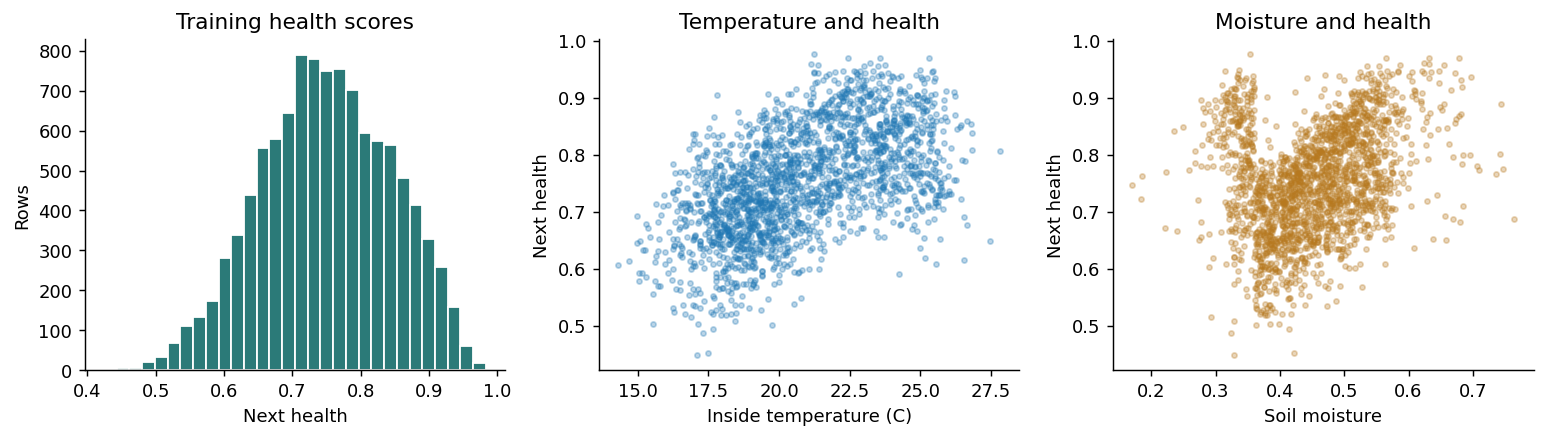

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes[0].hist(y, bins=30, color='#2b7a78', edgecolor='white')
axes[0].set(title='Training health scores', xlabel='Next health', ylabel='Rows')
sample = data.sample(n=2000, random_state=SEED)
axes[1].scatter(sample.inside_temp_c, sample[TARGET], s=8, alpha=0.3)
axes[1].set(title='Temperature and health', xlabel='Inside temperature (C)', ylabel='Next health')
axes[2].scatter(sample.soil_moisture, sample[TARGET], s=8, alpha=0.3, color='#b7791f')
axes[2].set(title='Moisture and health', xlabel='Soil moisture', ylabel='Next health')
save_plot('training_eda')


The scatter plots suggest that a single straight-line relationship may be too simple. This motivates comparing linear regression with a tree and a nonlinear SVR. These associations do not establish cause and effect.

## 2. Prepare the inputs and choose fair validation
Randomly splitting individual rows would put nearby observations from the same episode in both training and assessment. I use **five-fold GroupKFold**, with `episode_id` as the group. Each fold fits on 144 whole episodes and assesses on 36 different episodes. Every model uses the same folds.

Preprocessing stays inside a scikit-learn pipeline, so it is fitted separately on each fold's training data. Categorical inputs use one-hot encoding. Ridge and SVR also standardise numeric inputs; trees do not need scaling. Median/mode imputers allow future missing inputs, although none are present here. Their reliability with real sensor failures has not been tested.


In [5]:
cv = GroupKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(cv.split(X, y, groups))
fold_summary = []
for number, (fit, assess) in enumerate(folds, start=1):
    assert set(groups.iloc[fit]).isdisjoint(set(groups.iloc[assess]))
    fold_summary.append({'fold': number, 'fit_episodes': groups.iloc[fit].nunique(),
                         'assessment_episodes': groups.iloc[assess].nunique()})
display(pd.DataFrame(fold_summary))

def make_pipeline(model, features=FEATURES, scale=True):
    numeric = [name for name in features if name not in CATEGORICAL]
    steps = [('impute', SimpleImputer(strategy='median'))]
    if scale:
        steps.append(('scale', StandardScaler()))
    categorical = Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                           ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
    preparation = ColumnTransformer([('numeric', Pipeline(steps), numeric),
                                     ('categorical', categorical, CATEGORICAL)])
    return Pipeline([('prepare', preparation), ('model', model)])

SCORING = {'rmse': 'neg_root_mean_squared_error',
           'mae': 'neg_mean_absolute_error', 'r2': 'r2'}


,fold,fit_episodes,assessment_episodes
0,1,144,36
1,2,144,36
2,3,144,36
3,4,144,36
4,5,144,36


## 3. Compare a small set of classical models
- **Mean baseline:** checks whether the models improve on a constant training mean.
- **Ridge regression:** a simple linear model with regularisation.
- **Decision tree:** captures thresholds and interactions; depth and minimum leaf size limit overfitting.
- **RBF SVR:** tests a smooth nonlinear relationship. `C` controls the penalty on errors, `epsilon` sets an insensitive error range and `gamma` controls the kernel's locality.

I use a small grid of 16 configurations. Ridge tests `alpha = 0.1, 10, 100`. The tree tests depth `4, 8, 12, None` and minimum leaf size `10, 40`. SVR tests `epsilon = 0.01, 0.03` and `gamma = 'scale', 0.03`, with `C = 1` fixed to keep the comparison manageable.

**Selection metric:** mean cross-validation RMSE, which gives larger errors greater weight. MAE measures typical absolute error, and R-squared measures fit relative to the target's variation. Errors are in 0-1 health-score units. Fold standard deviation describes variation across the five folds; it is not a confidence interval.


In [6]:
experiments = {
    'Mean baseline': (DummyRegressor(strategy='mean'), {}, False),
    'Ridge': (Ridge(), {'model__alpha': [0.1, 10, 100]}, True),
    'Decision tree': (DecisionTreeRegressor(random_state=SEED),
                      {'model__max_depth': [4, 8, 12, None], 'model__min_samples_leaf': [10, 40]}, False),
    'RBF SVR': (SVR(kernel='rbf', C=1, cache_size=512),
                {'model__epsilon': [0.01, 0.03], 'model__gamma': ['scale', 0.03]}, True)
}
searches, comparisons, records = {}, [], []
for name, (model, grid, scale) in experiments.items():
    search = GridSearchCV(make_pipeline(model, scale=scale), grid, cv=folds,
                          scoring=SCORING, refit='rmse', return_train_score=True,
                          n_jobs=1, error_score='raise')
    search.fit(X, y)
    searches[name] = search
    result = pd.DataFrame(search.cv_results_)
    best = result.iloc[search.best_index_]
    comparisons.append({'model': name, 'train_RMSE': -best.mean_train_rmse,
                        'CV_RMSE': -best.mean_test_rmse, 'fold_SD': best.std_test_rmse,
                        'CV_MAE': -best.mean_test_mae, 'CV_R2': best.mean_test_r2,
                        'best_parameters': search.best_params_})
    for _, row in result.iterrows():
        records.append({'model': name, 'parameters': str(row.params),
                        'train_RMSE': -row.mean_train_rmse, 'CV_RMSE': -row.mean_test_rmse})
    print(name, 'completed; best CV RMSE:', round(-best.mean_test_rmse, 6))

comparison = pd.DataFrame(comparisons).sort_values('CV_RMSE').reset_index(drop=True)
experiment_log = pd.DataFrame(records)
display(comparison.round(6))
display(experiment_log.round(6))
comparison.to_csv(RESULTS / 'model_comparison.csv', index=False)
experiment_log.to_csv(RESULTS / 'experiment_log.csv', index=False)


Mean baseline completed; best CV RMSE: 0.09631
Ridge completed; best CV RMSE: 0.06735
Decision tree completed; best CV RMSE: 0.055399
RBF SVR completed; best CV RMSE: 0.058148


,model,train_RMSE,CV_RMSE,fold_SD,CV_MAE,CV_R2,best_parameters
0,Decision tree,0.049222,0.055399,0.000496,0.041749,0.667604,"{'model__max_depth': 12, 'model__min_samples_l..."
1,RBF SVR,0.053070,0.058148,0.000655,0.044341,0.633736,"{'model__epsilon': 0.03, 'model__gamma': 0.03}"
2,Ridge,0.067118,0.067350,0.000658,0.053914,0.509127,{'model__alpha': 0.1}
3,Mean baseline,0.096274,0.096310,0.002006,0.078633,-0.002910,{}


,model,parameters,train_RMSE,CV_RMSE
0,Mean baseline,{},0.096274,0.096310
1,Ridge,{'model__alpha': 0.1},0.067118,0.067350
2,Ridge,{'model__alpha': 10},0.067133,0.067364
3,Ridge,{'model__alpha': 100},0.067387,0.067607
4,Decision tree,"{'model__max_depth': 4, 'model__min_samples_le...",0.059968,0.061448
5,Decision tree,"{'model__max_depth': 4, 'model__min_samples_le...",0.059968,0.061448
6,Decision tree,"{'model__max_depth': 8, 'model__min_samples_le...",0.047056,0.056309
7,Decision tree,"{'model__max_depth': 8, 'model__min_samples_le...",0.049826,0.055469
8,Decision tree,"{'model__max_depth': 12, 'model__min_samples_l...",0.040562,0.058485
9,Decision tree,"{'model__max_depth': 12, 'model__min_samples_l...",0.049222,0.055399


**Results:** the tree has the lowest grouped-CV RMSE (0.055399), followed by SVR (0.058148), Ridge (0.067350) and the mean baseline (0.096310). The tree uses maximum depth 12 and minimum leaf size 40. An unrestricted depth with leaf size 40 gives the same score; the depth limit is retained.

**Approaches that did not work as well:** a depth-4 tree underfits (CV RMSE about 0.06145). Allowing unrestricted depth with leaf size 10 reduces training RMSE to about 0.04005 but increases CV RMSE to about 0.05871, indicating overfitting. Ridge's poorer score suggests that linear additive effects miss useful patterns. SVR is competitive but does not beat the tree in this experiment. Its search is deliberately limited, so this is not a claim that trees always outperform SVR.


## 4. Check one useful feature decision
The biomass and fruit indices are synthetic accumulated quantities whose measurement in a real greenhouse is uncertain. I repeat the selected tree's grouped validation without them, keeping the tree settings and folds fixed. This tests whether they are necessary rather than automatically using every column.


In [7]:
assert comparison.iloc[0]['model'] == 'Decision tree'
tree_parameters = searches['Decision tree'].best_params_
FINAL_FEATURES = [name for name in FEATURES if name not in ['biomass_index', 'fruit_index']]
reduced_tree = make_pipeline(DecisionTreeRegressor(random_state=SEED), FINAL_FEATURES, scale=False)
reduced_tree.set_params(**tree_parameters)
reduced_scores = cross_validate(reduced_tree, data[FINAL_FEATURES], y, cv=folds,
                                scoring=SCORING, n_jobs=1, error_score='raise')
full_row = comparison.loc[comparison.model.eq('Decision tree')].iloc[0]
feature_check = pd.DataFrame([
    {'features': 'Full candidate set', 'raw_features': len(FEATURES),
     'CV_RMSE': full_row.CV_RMSE, 'CV_MAE': full_row.CV_MAE},
    {'features': 'Without biomass/fruit', 'raw_features': len(FINAL_FEATURES),
     'CV_RMSE': -reduced_scores['test_rmse'].mean(), 'CV_MAE': -reduced_scores['test_mae'].mean()}
])
display(feature_check.round(6))
feature_check.to_csv(RESULTS / 'feature_check.csv', index=False)
final_model = clone(reduced_tree).fit(data[FINAL_FEATURES], y)
print('Final settings:', tree_parameters)
print('Final inputs:', FINAL_FEATURES)


,features,raw_features,CV_RMSE,CV_MAE
0,Full candidate set,14,0.055399,0.041749
1,Without biomass/fruit,12,0.055189,0.041504


Final settings: {'model__max_depth': 12, 'model__min_samples_leaf': 40}
Final inputs: ['day', 'outside_temp_c', 'outside_humidity_pct', 'solar_w_m2', 'inside_temp_c', 'inside_humidity_pct', 'co2_ppm', 'soil_moisture', 'vpd_kpa', 'cultivar', 'season', 'action_name']


Removing the two crop indices changes CV RMSE from **0.055399 to 0.055189**. The difference is small and is not evidence of a statistically significant improvement. It shows no practical loss in this check, so the final model uses the **12 remaining inputs**. They are easier to justify as available information.

The final tree settings and feature list are now fixed. The validation file is used below to evaluate this choice, not to adjust it.


## 5. Evaluate the final model on unseen episodes


In [8]:
validation_raw = read_csv('validation.csv')
validation_check = check_data(validation_raw, 'Final holdout')
assert set(train_raw.episode_id).isdisjoint(set(validation_raw.episode_id))
validation = validation_raw.dropna(subset=[TARGET]).reset_index(drop=True)
actual = validation[TARGET].to_numpy()
predicted = final_model.predict(validation[FINAL_FEATURES])
baseline_model = DummyRegressor(strategy='mean').fit(data[FINAL_FEATURES], y)
baseline_predicted = baseline_model.predict(validation[FINAL_FEATURES])

def metrics(actual, predicted):
    return {'RMSE': root_mean_squared_error(actual, predicted),
            'MAE': mean_absolute_error(actual, predicted), 'R2': r2_score(actual, predicted)}

holdout_metrics = pd.DataFrame([{'model': 'Mean baseline', **metrics(actual, baseline_predicted)},
                               {'model': 'Final decision tree', **metrics(actual, predicted)}])
display(pd.DataFrame([train_check, validation_check]))
display(holdout_metrics.round(6))
reduction = 1 - holdout_metrics.iloc[1].RMSE / holdout_metrics.iloc[0].RMSE
print(f'RMSE reduction versus mean baseline: {100 * reduction:.2f}%')
print('Predictions outside [0, 1]:', np.count_nonzero((predicted < 0) | (predicted > 1)))
holdout_metrics.to_csv(RESULTS / 'holdout_metrics.csv', index=False)
predictions = validation[['episode_id', 'day', 'season', 'cultivar', 'action_name']].copy()
predictions['actual'] = actual
predictions['predicted'] = predicted
predictions['residual'] = predicted - actual
predictions.to_csv(RESULTS / 'holdout_predictions.csv', index=False)


,split,raw_rows,columns,episodes,missing_targets,usable_rows,missing_inputs
0,Training,10800,31,180,180,10620,0
1,Final holdout,1800,31,30,30,1770,0


,model,RMSE,MAE,R2
0,Mean baseline,0.093908,0.076988,-0.000261
1,Final decision tree,0.055255,0.041652,0.653701


RMSE reduction versus mean baseline: 41.16%
Predictions outside [0, 1]: 0


The holdout contains **1,770 labelled rows from 30 new episodes**. Final RMSE is **0.055255**, MAE **0.041652**, and R-squared **0.653701**. RMSE is about **41.2% lower** than the constant baseline's 0.093908. MAE means an average absolute error of about 0.042 health-score units, rather than a classification accuracy. The holdout RMSE is close to the reduced tree's CV result (0.055189).

The predictions stay within 0-1 without clipping. These scores are row-level summaries; consecutive rows within an episode are related. They are not 1,770 independent greenhouse trials.


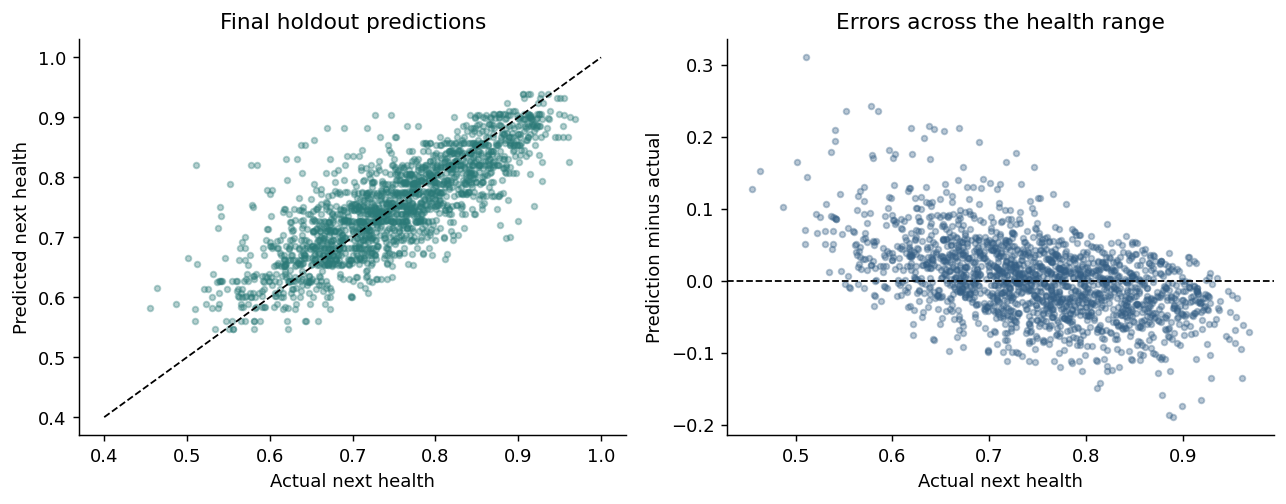

,season,rows,episodes,RMSE,MAE,R2
0,cool,531,9,0.058079,0.044940,0.562331
1,mild,767,13,0.055821,0.042846,0.570777
2,warm,472,8,0.050899,0.036012,0.537249


,rows,episodes,RMSE,MAE,R2,mean_overprediction
0,105,20,0.093281,0.070891,-9.413932,0.06775


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(actual, predicted, s=10, alpha=0.35, color='#2b7a78')
axes[0].plot([0.4, 1.0], [0.4, 1.0], 'k--', linewidth=1)
axes[0].set(xlabel='Actual next health', ylabel='Predicted next health', title='Final holdout predictions')
axes[1].scatter(actual, predicted - actual, s=10, alpha=0.35, color='#355f85')
axes[1].axhline(0, color='black', linestyle='--', linewidth=1)
axes[1].set(xlabel='Actual next health', ylabel='Prediction minus actual', title='Errors across the health range')
save_plot('holdout_diagnostics')

season_rows = []
for season, rows in predictions.groupby('season'):
    season_rows.append({'season': season, 'rows': len(rows), 'episodes': rows.episode_id.nunique(),
                        **metrics(rows.actual, rows.predicted)})
season_results = pd.DataFrame(season_rows)
display(season_results.round(6))
low_health = predictions.loc[predictions.actual < 0.6]
low_result = {'rows': len(low_health), 'episodes': low_health.episode_id.nunique(),
              **metrics(low_health.actual, low_health.predicted),
              'mean_overprediction': low_health.residual.mean()}
display(pd.DataFrame([low_result]).round(6))
season_results.to_csv(RESULTS / 'season_results.csv', index=False)
pd.DataFrame([low_result]).to_csv(RESULTS / 'low_health_results.csv', index=False)


## 6. Interpret the results and limitations
The residual plot shows an important failure: the model tends to predict too high when actual health is low. For the **105 rows below 0.6**, across 20 episodes, RMSE rises to **0.093281** and mean overprediction is **0.067750**. The 0.6 cutoff is a diagnostic example, not a validated crop-health threshold. A low-error average therefore does not make this a dependable stress alarm.

Season RMSE ranges from about **0.050899 to 0.058079**. The groups contain only 8-13 episodes each, so these differences need cautious interpretation. Rare actions also have too few examples for strong action-specific claims. No model changes are made after these holdout diagnostics.

The tree is a reasonable final choice because it captures nonlinear patterns, beats a simple baseline and has the best score among the models tested. Minimum leaf size 40 controls overfitting. Its piecewise predictions can miss extreme health values. The tiny CV difference between depths 8 and 12 also means that 12 should not be presented as uniquely optimal.

This dataset is synthetic. Real sensors, different cultivars, operating policies and unseen environmental conditions may behave differently. Latent health provides a simulator label; obtaining reliable labels for real crops is unresolved. Numeric imputation does not establish resilience to sensor failure. The logged actions support prediction under those actions, not causal recommendations. More real episodes, more examples of poor health and external validation would be needed before use in a greenhouse.

For **Part B**, keep the same next-step target and episode-based evaluation and add the supplied crop images. Compare the image model with this tabular baseline on the same held-out episodes. Image-index alignment and the availability of images at the current step must be checked.


## Final checks and references
The following checks confirm the split, the 16 recorded configurations, the final settings and the absence of future/latent inputs. Report values come from the saved tables and figures above. All modelling code is in this notebook.

1. Supplied COMP3032 two-part project brief and `data_dictionary.csv`.
2. scikit-learn: [common pitfalls and pipelines](https://scikit-learn.org/1.8/common_pitfalls.html).
3. scikit-learn: [GroupKFold](https://scikit-learn.org/1.8/modules/generated/sklearn.model_selection.GroupKFold.html).
4. scikit-learn: [support vector regression](https://scikit-learn.org/1.8/modules/generated/sklearn.svm.SVR.html).


In [10]:
assert len(experiment_log) == 16
assert len(data) == 10620 and len(validation) == 1770
assert data.episode_id.nunique() == 180 and validation.episode_id.nunique() == 30
assert len(FINAL_FEATURES) == 12
assert not any(name.startswith('next_') for name in FINAL_FEATURES)
assert not set(FINAL_FEATURES) & {'health_score', 'disease_severity', 'reward', 'episode_id', 'image_index'}
assert tree_parameters == {'model__max_depth': 12, 'model__min_samples_leaf': 40}
assert np.isfinite(predicted).all()
print('All final checks passed. Report tables and plots are saved above.')


All final checks passed. Report tables and plots are saved above.
